# WatchWise: cleaning and a first look

First pass on the Rotten Tomatoes dump for the movie assistant. I want to see how messy the scores are, how often critics and audiences disagree, and where the data gets thin. The scrape stops in 2020, so newer movies have to come from TMDB later.

## 0. Setup

Add the repo root to the path so I can import `src` the same way the scripts do.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

here = Path.cwd().resolve()
root = here if (here / "src").exists() else here.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.cleaning import (
    clean_movies,
    clean_reviews,
    join_and_filter,
    load_raw,
    save_processed,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 120)

## 1. Load raw data

Two files. One row per movie, one row per critic review, joined on `rotten_tomatoes_link`.

In [2]:
movies_raw, reviews_raw = load_raw()
print("movies shape:", movies_raw.shape)
print("reviews shape:", reviews_raw.shape)

load_raw | movies=17,712 | reviews=1,130,017
movies shape: (17712, 22)
reviews shape: (1130017, 8)


In [3]:
movies_raw.head()

,rotten_tomatoes_link,movie_title,movie_info,critics_consensus,content_rating,genres,directors,authors,actors,original_release_date,...,production_company,tomatometer_status,tomatometer_rating,tomatometer_count,audience_status,audience_rating,audience_count,tomatometer_top_critics_count,tomatometer_fresh_critics_count,tomatometer_rotten_critics_count
0,m/0814255,Percy Jackson & the Olympians: The Lightning Thief,"Always trouble-prone, the life of teenager Percy Jackson (Logan Lerman) gets a lot more complicated when he learns h...","Though it may seem like just another Harry Potter knockoff, Percy Jackson benefits from a strong supporting cast, a ...",PG,"Action & Adventure, Comedy, Drama, Science Fiction & Fantasy",Chris Columbus,"Craig Titley, Chris Columbus, Rick Riordan","Logan Lerman, Brandon T. Jackson, Alexandra Daddario, Jake Abel, Sean Bean, Pierce Brosnan, Steve Coogan, Rosario Da...",2010-02-12,...,20th Century Fox,Rotten,49.0,149.0,Spilled,53.0,254421.0,43,73,76
1,m/0878835,Please Give,Kate (Catherine Keener) and her husband Alex (Oliver Platt) are wealthy New Yorkers who prowl estate sales and make ...,"Nicole Holofcener's newest might seem slight in places, but its rendering of complex characters in a conflicted econ...",R,Comedy,Nicole Holofcener,Nicole Holofcener,"Catherine Keener, Amanda Peet, Oliver Platt, Rebecca Hall, Sarah Steele, Ann Morgan Guilbert, Kevin Corrigan, Lois S...",2010-04-30,...,Sony Pictures Classics,Certified-Fresh,87.0,142.0,Upright,64.0,11574.0,44,123,19
2,m/10,10,"A successful, middle-aged Hollywood songwriter falls hopelessly in love with the woman of his dreams, and even follo...","Blake Edwards' bawdy comedy may not score a perfect 10, but Dudley Moore's self-deprecating performance makes this m...",R,"Comedy, Romance",Blake Edwards,Blake Edwards,"Dudley Moore, Bo Derek, Julie Andrews, Robert Webber, Dee Wallace, Sam Jones III, Sam J. Jones, Brian Dennehy, Max S...",1979-10-05,...,Waner Bros.,Fresh,67.0,24.0,Spilled,53.0,14684.0,2,16,8
3,m/1000013-12_angry_men,12 Angry Men (Twelve Angry Men),"Following the closing arguments in a murder trial, the 12 members of the jury must deliberate, with a guilty verdict...","Sidney Lumet's feature debut is a superbly written, dramatically effective courtroom thriller that rightfully stands...",NR,"Classics, Drama",Sidney Lumet,Reginald Rose,"Martin Balsam, John Fiedler, Lee J. Cobb, E.G. Marshall, Jack Klugman, Edward Binns, Jack Warden, Henry Fonda, Josep...",1957-04-13,...,Criterion Collection,Certified-Fresh,100.0,54.0,Upright,97.0,105386.0,6,54,0
4,m/1000079-20000_leagues_under_the_sea,"20,000 Leagues Under The Sea","In 1866, Professor Pierre M. Aronnax (Paul Lukas) and his assistant Conseil (Peter Lorre), stranded in San Francisco...","One of Disney's finest live-action adventures, 20,000 Leagues Under the Sea brings Jules Verne's classic sci-fi tale...",G,"Action & Adventure, Drama, Kids & Family",Richard Fleischer,Earl Felton,"James Mason, Kirk Douglas, Paul Lukas, Peter Lorre, Robert J. Wilke, Carleton Young, Bob Wilke, Ted de Corsia, Percy...",1954-01-01,...,Disney,Fresh,89.0,27.0,Upright,74.0,68918.0,5,24,3


In [4]:
reviews_raw.head()

,rotten_tomatoes_link,critic_name,top_critic,publisher_name,review_type,review_score,review_date,review_content
0,m/0814255,Andrew L. Urban,False,Urban Cinefile,Fresh,NaN,2010-02-06,A fantasy adventure that fuses Greek mythology to contemporary American places and values. Anyone around 15 (give or...
1,m/0814255,Louise Keller,False,Urban Cinefile,Fresh,NaN,2010-02-06,"Uma Thurman as Medusa, the gorgon with a coiffure of writhing snakes and stone-inducing hypnotic gaze is one of the ..."
2,m/0814255,NaN,False,FILMINK (Australia),Fresh,NaN,2010-02-09,"With a top-notch cast and dazzling special effects, this will tide the teens over until the next Harry Potter instal..."
3,m/0814255,Ben McEachen,False,Sunday Mail (Australia),Fresh,3.5/5,2010-02-09,"Whether audiences will get behind The Lightning Thief is hard to predict. Overall, it's an entertaining introduction..."
4,m/0814255,Ethan Alter,True,Hollywood Reporter,Rotten,NaN,2010-02-10,"What's really lacking in The Lightning Thief is a genuine sense of wonder, the same thing that brings viewers back t..."


In [5]:
print("missing values, movies")
display(movies_raw.isna().sum().rename("missing").to_frame())
print("missing values, reviews")
display(reviews_raw.isna().sum().rename("missing").to_frame())

missing values, movies


,missing
rotten_tomatoes_link,0
movie_title,0
movie_info,321
critics_consensus,8578
content_rating,0
genres,19
directors,194
authors,1542
actors,352
original_release_date,1166


missing values, reviews


,missing
rotten_tomatoes_link,0
critic_name,18529
top_critic,0
publisher_name,0
review_type,0
review_score,305936
review_date,0
review_content,65806


Every movie has a title, so that filter will not do much. `critics_consensus` is blank on 8,578 movies, a bit under half. On the review file, `review_score` is missing 305,936 times and `review_content` is missing 65,806 times. Those empty reviews are the ones cleaning should drop.

## 2. Cleaning

Drop untitled movies, empty review text, and exact duplicate reviews. Then keep only movies that still have at least one review, and add the critic minus audience gap.

In [6]:
movies_clean = clean_movies(movies_raw)
reviews_clean = clean_reviews(reviews_raw)
movies, reviews = join_and_filter(movies_clean, reviews_clean)

summary = pd.DataFrame(
    [
        {"step": "raw load", "movies": len(movies_raw), "reviews": len(reviews_raw)},
        {"step": "after movie cleaning", "movies": len(movies_clean), "reviews": len(reviews_raw)},
        {"step": "after review cleaning", "movies": len(movies_clean), "reviews": len(reviews_clean)},
        {"step": "after join (at least 1 review)", "movies": len(movies), "reviews": len(reviews)},
    ]
)
summary

clean_movies before | movies=17,712
clean_movies after dropping missing titles | movies=17,712
clean_movies after | movies=17,712
clean_movies removed 0 rows
clean_reviews before | reviews=1,130,017


clean_reviews after dropping empty text | reviews=1,064,211


clean_reviews after dropping duplicate reviews | reviews=951,814


clean_reviews after | reviews=951,814
clean_reviews removed 178,203 rows
join_and_filter before | movies=17,712 | reviews=951,814


join_and_filter after | movies=17,691 | reviews=951,712
movies with at least 1 review: 17,691


,step,movies,reviews
0,raw load,17712,1130017
1,after movie cleaning,17712,1130017
2,after review cleaning,17712,951814
3,after join (at least 1 review),17691,951712


Movie cleaning removed nothing: 17,712 rows in, 17,712 out. Review cleaning is where the rows go. Empty text takes it from 1,130,017 to 1,064,211, and duplicate (link, critic, text) rows take it to 951,814. The join then drops 21 movies with no review left and 102 reviews whose link is not in the movie file. What I save is 17,691 movies and 951,712 reviews.

## 3. Review score formats

`review_score` is a mess of fractions, letter grades, blanks, and the occasional bare number. `score_norm` maps the ones with a clear scale onto 0 to 1.

In [7]:
raw_scores = (
    reviews_raw["review_score"]
    .fillna("(missing)")
    .astype(str)
    .str.strip()
    .replace({"": "(missing)"})
)
print("top 20 raw review_score values (whole file)")
display(raw_scores.value_counts().head(20).rename("count").to_frame())

nonempty = raw_scores[raw_scores != "(missing)"]
print("top 20 non-empty raw scores")
display(nonempty.value_counts().head(20).rename("count").to_frame())

score_text = reviews["review_score"]
blank = score_text.isna() | score_text.astype(str).str.strip().eq("") | score_text.astype(str).str.lower().isin(["nan", "none"])
normalized = int(reviews["score_norm"].notna().sum())
not_normalized = int(reviews["score_norm"].isna().sum())
failed_nonblank = int((~blank & reviews["score_norm"].isna()).sum())
print(f"kept reviews: {len(reviews):,}")
print(f"score_norm filled: {normalized:,}")
print(f"score_norm is None: {not_normalized:,}")
print(f"of those Nones, blank score: {int(blank.sum()):,}")
print(f"of those Nones, non-blank but unparsed: {failed_nonblank:,}")

top 20 raw review_score values (whole file)


,count
review_score,
(missing),305936
3/5,90273
4/5,83659
3/4,72366
2/5,60174
2/4,47546
2.5/4,44994
3.5/4,34371
3.5/5,30885


top 20 non-empty raw scores


,count
review_score,
3/5,90273
4/5,83659
3/4,72366
2/5,60174
2/4,47546
2.5/4,44994
3.5/4,34371
3.5/5,30885
B,24358


kept reviews: 951,712
score_norm filled: 677,158
score_norm is None: 274,554
of those Nones, blank score: 273,102
of those Nones, non-blank but unparsed: 1,452


Blank is the most common raw value (305,936). After that it is fractions (`3/5`, `4/5`, `3/4`) and letter grades (`B`, `B+`, `C`). On the reviews I keep, 677,158 get a 0 to 1 score and 274,554 stay None. Almost all of those Nones are blanks. Only 1,452 non-blank scores fail, mostly bare numbers like `3` or `4` with no scale, which I left as None on purpose.

## 4. EDA

### Reviews per movie

movies: 17,691
median reviews per movie: 23
mean reviews per movie: 53.8
max: 574
under 20 reviews: 7,922 (44.8%)
exactly 1 review: 78


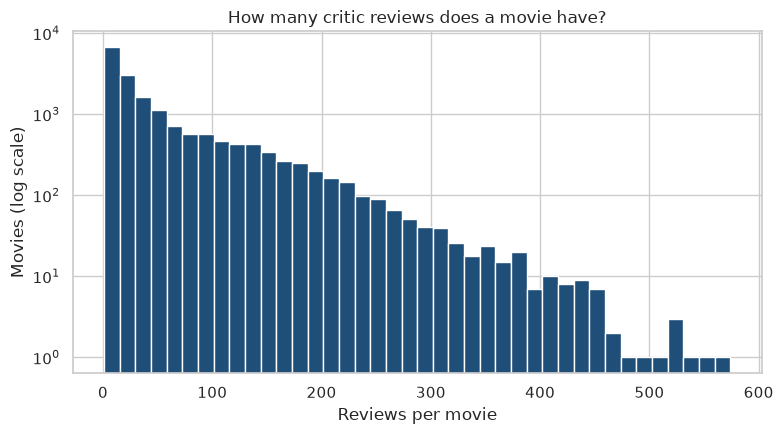

In [8]:
per_movie = reviews.groupby("rotten_tomatoes_link").size()
print(f"movies: {len(per_movie):,}")
print(f"median reviews per movie: {per_movie.median():.0f}")
print(f"mean reviews per movie: {per_movie.mean():.1f}")
print(f"max: {int(per_movie.max())}")
print(f"under 20 reviews: {(per_movie < 20).sum():,} ({(per_movie < 20).mean():.1%})")
print(f"exactly 1 review: {(per_movie == 1).sum():,}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(per_movie, bins=40, color="#1f4e79")
ax.set_yscale("log")
ax.set_title("How many critic reviews does a movie have?")
ax.set_xlabel("Reviews per movie")
ax.set_ylabel("Movies (log scale)")
fig.tight_layout()
plt.show()

The median movie has 23 critic reviews, but 44.8% have fewer than 20 and the tail runs out to 574. A lot of titles will not have much text to lean on.

### Fresh vs rotten

review_type
Fresh     608877
Rotten    342835
fresh share: 64.0%


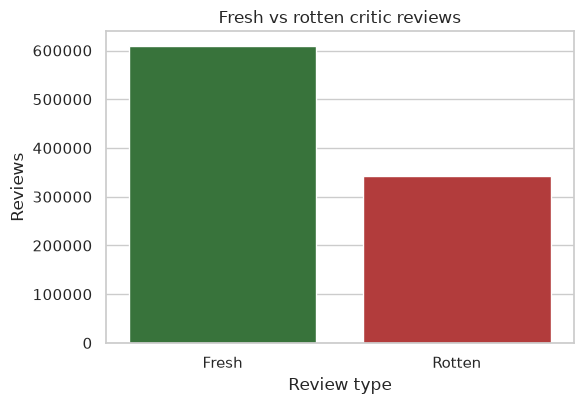

In [9]:
type_counts = reviews["review_type"].value_counts()
print(type_counts.to_string())
print(f"fresh share: {reviews['is_fresh'].mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 4.2))
order = ["Fresh", "Rotten"]
plot_df = pd.DataFrame({"review_type": order, "reviews": [int(type_counts[k]) for k in order]})
sns.barplot(
    data=plot_df,
    x="review_type",
    y="reviews",
    hue="review_type",
    palette={"Fresh": "#2e7d32", "Rotten": "#c62828"},
    legend=False,
    ax=ax,
)
ax.set_title("Fresh vs rotten critic reviews")
ax.set_xlabel("Review type")
ax.set_ylabel("Reviews")
fig.tight_layout()
plt.show()

Fresh wins, 608,877 to 342,835, about 64.0% of the blurbs we kept. Having a review is not the same thing as the movie being good.

### Movies per release year

year min: 1914
year max: 2020
missing release year: 1,160
busiest years:
release_year
2014    745
2013    703
2012    669
2015    650
2018    649


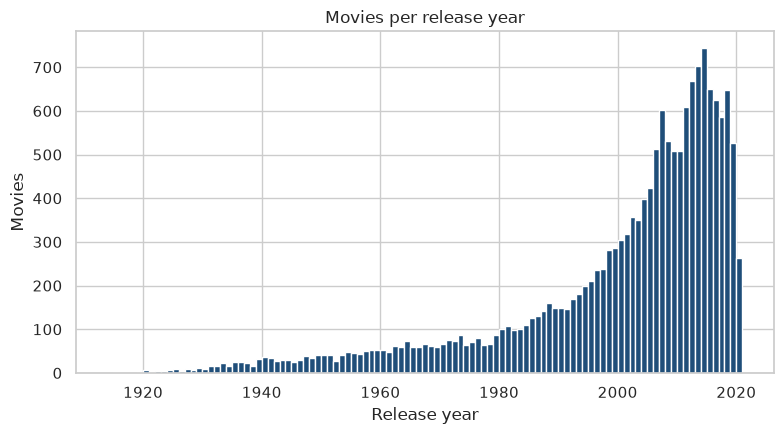

In [10]:
years = movies["release_year"].dropna().astype(int)
print(f"year min: {int(years.min())}")
print(f"year max: {int(years.max())}")
print(f"missing release year: {int(movies['release_year'].isna().sum()):,}")
print("busiest years:")
print(years.value_counts().head(5).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(years, bins=range(int(years.min()), int(years.max()) + 2), color="#1f4e79")
ax.set_title("Movies per release year")
ax.set_xlabel("Release year")
ax.set_ylabel("Movies")
fig.tight_layout()
plt.show()

The file runs from 1914 through 2020, and it piles up in the 2010s (2014 is the busiest year, 745 movies). 1,160 movies have no release year. Nothing here is newer than 2020, which is why TMDB has to cover new releases.

### Critic vs audience gap

`critic_audience_gap` is tomatometer minus audience rating. Positive means critics liked it more.

movies with a gap: 17,391
missing gap: 300


median: 2
mean: 0.2
std: 21.6
min: -95
max: 86
more than 20 points apart: 5,609


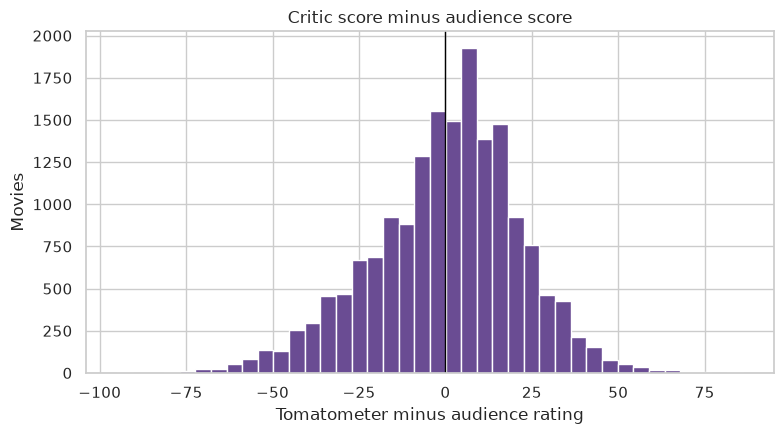

critics liked it way more (highest gap)


,movie_title,release_year,tomatometer_rating,audience_rating,critic_audience_gap,tomatometer_count,audience_count
11507,Outside the Law,2001,86.0,0.0,86.0,7.0,89.0
6133,Everybody Knows... Elizabeth Murray,2017,100.0,17.0,83.0,6.0,31.0
16833,Vengeance Valley,1951,100.0,18.0,82.0,5.0,915.0
9073,Knock Down the House,2019,99.0,20.0,79.0,103.0,2905.0
10975,Never Rarely Sometimes Always,2020,99.0,20.0,79.0,195.0,750.0
7446,Hannah Gadsby: Nanette,2018,100.0,25.0,75.0,48.0,1754.0
2929,Artik,2019,100.0,26.0,74.0,6.0,23.0
9407,Leslie Jones: Time Machine,2020,100.0,27.0,73.0,6.0,56.0
16404,Traffic Stop,<NA>,100.0,27.0,73.0,8.0,55.0
1561,Angel Rodriguez,<NA>,83.0,11.0,72.0,6.0,115.0


audiences liked it way more (lowest gap)


,movie_title,release_year,tomatometer_rating,audience_rating,critic_audience_gap,tomatometer_count,audience_count
2050,96 Souls,2017,0.0,95.0,-95.0,6.0,140.0
7541,Hating Breitbart,2012,0.0,92.0,-92.0,9.0,804.0
8481,Is That a Gun in Your Pocket?,2016,0.0,92.0,-92.0,11.0,379.0
14469,The After Party,2018,0.0,87.0,-87.0,5.0,393.0
1783,Home,2011,0.0,86.0,-86.0,5.0,1887.0
1176,Fall,1997,0.0,84.0,-84.0,7.0,1118.0
15482,The Music of Silence,2018,0.0,81.0,-81.0,17.0,115.0
736,Sparkle,1976,10.0,90.0,-80.0,10.0,4581.0
2531,All Relative,2014,10.0,90.0,-80.0,10.0,866.0
10865,Mysteries Of The Jesus Prayer,<NA>,20.0,100.0,-80.0,5.0,20.0


In [11]:
gap = movies["critic_audience_gap"].dropna()
print(f"movies with a gap: {len(gap):,}")
print(f"missing gap: {int(movies['critic_audience_gap'].isna().sum()):,}")
print(f"median: {gap.median():.0f}")
print(f"mean: {gap.mean():.1f}")
print(f"std: {gap.std():.1f}")
print(f"min: {gap.min():.0f}")
print(f"max: {gap.max():.0f}")
print(f"more than 20 points apart: {(gap.abs() > 20).sum():,}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(gap, bins=40, color="#6a4c93")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Critic score minus audience score")
ax.set_xlabel("Tomatometer minus audience rating")
ax.set_ylabel("Movies")
fig.tight_layout()
plt.show()

cols = [
    "movie_title",
    "release_year",
    "tomatometer_rating",
    "audience_rating",
    "critic_audience_gap",
    "tomatometer_count",
    "audience_count",
]
both = movies.dropna(subset=["critic_audience_gap"])
print("critics liked it way more (highest gap)")
display(both.nlargest(10, "critic_audience_gap")[cols])
print("audiences liked it way more (lowest gap)")
display(both.nsmallest(10, "critic_audience_gap")[cols])

The gap is centered near 0 (median 2, mean 0.2) but 5,609 movies are still more than 20 points apart. The extremes mix tiny critic counts (Outside the Law has 7) with real splits (Knock Down the House is 99 vs 20 on 103 reviews), so the counts have to sit next to the gap.

### Tomatometer vs audience rating

movies with both scores: 17,391
correlation: 0.654
mean tomatometer: 60.8
mean audience: 60.6


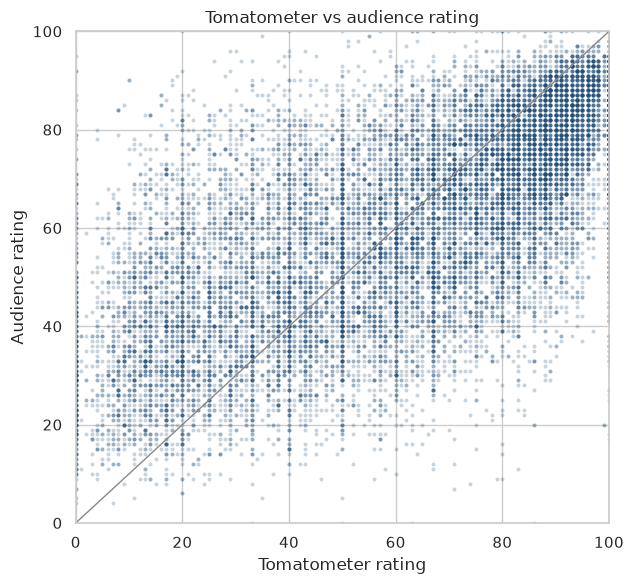

In [12]:
scored = movies.dropna(subset=["tomatometer_rating", "audience_rating"])
corr = scored["tomatometer_rating"].corr(scored["audience_rating"])
print(f"movies with both scores: {len(scored):,}")
print(f"correlation: {corr:.3f}")
print(f"mean tomatometer: {scored['tomatometer_rating'].mean():.1f}")
print(f"mean audience: {scored['audience_rating'].mean():.1f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(
    scored["tomatometer_rating"],
    scored["audience_rating"],
    s=8,
    alpha=0.25,
    color="#1f4e79",
    linewidths=0,
)
ax.plot([0, 100], [0, 100], color="#888888", linewidth=1)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_title("Tomatometer vs audience rating")
ax.set_xlabel("Tomatometer rating")
ax.set_ylabel("Audience rating")
fig.tight_layout()
plt.show()

The two scores move together (correlation 0.654) and both average about 61, but the cloud is wide of the diagonal. That spread is the disagreement the assistant should point out.

### Review length

median words: 21
mean words: 21.4
90th percentile: 34
max: 55
under 20 words: 43.9%


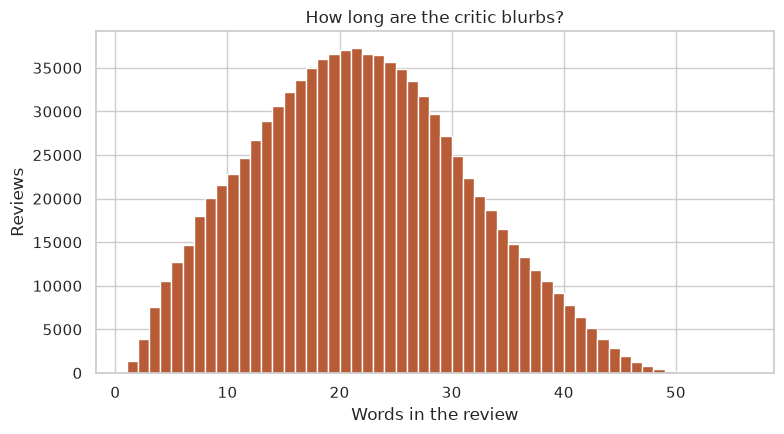

In [13]:
words = reviews["review_content"].str.split().str.len()
print(f"median words: {words.median():.0f}")
print(f"mean words: {words.mean():.1f}")
print(f"90th percentile: {words.quantile(0.9):.0f}")
print(f"max: {int(words.max())}")
print(f"under 20 words: {(words < 20).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(words, bins=range(1, int(words.max()) + 2), color="#b85c38")
ax.set_title("How long are the critic blurbs?")
ax.set_xlabel("Words in the review")
ax.set_ylabel("Reviews")
fig.tight_layout()
plt.show()

These are short quotes, not essays. The median is 21 words, the 90th percentile is 34, and nothing in this file is longer than 55 words. Later retrieval is matching blurbs.

## 5. Duplicate titles

Same name, different year, often a totally different movie. This is why a lookup cannot be title only.

In [14]:
titled = movies.dropna(subset=["release_year"]).copy()
titled["title_key"] = titled["movie_title"].str.strip().str.lower()
year_n = titled.groupby("title_key")["release_year"].nunique()
multi = year_n[year_n > 1]
involved = titled[titled["title_key"].isin(multi.index)]
print(f"titles with more than one release year: {len(multi):,}")
print(f"movie rows those titles cover: {len(involved):,}")
print("titles with the most distinct years:")
print(year_n.sort_values(ascending=False).head(8).to_string())

examples = ["carrie", "a star is born", "little women", "home"]
for key in examples:
    rows = (
        titled.loc[
            titled["title_key"] == key,
            ["movie_title", "release_year", "tomatometer_rating", "audience_rating"],
        ]
        .drop_duplicates()
        .sort_values("release_year")
    )
    print(key)
    display(rows)

titles with more than one release year: 513
movie rows those titles cover: 1,072
titles with the most distinct years:
title_key
home                    5
a star is born          4
gloria                  4
alice in wonderland     4
robin hood              4
hamlet                  4
little women            4
the three musketeers    4
carrie


,movie_title,release_year,tomatometer_rating,audience_rating
4326,Carrie,1952,83.0,59.0
356,Carrie,1976,93.0,77.0
1413,Carrie,2002,20.0,50.0
4325,Carrie,2013,50.0,44.0


a star is born


,movie_title,release_year,tomatometer_rating,audience_rating
745,A Star Is Born,1937,100.0,78.0
746,A Star Is Born,1954,98.0,82.0
747,A Star is Born,1976,36.0,64.0
2218,A Star Is Born,2018,90.0,79.0


little women


,movie_title,release_year,tomatometer_rating,audience_rating
569,Little Women,1933,94.0,78.0
570,Little Women,1949,71.0,83.0
1022,Little Women,1994,92.0,84.0
9598,Little Women,2018,30.0,70.0


home


,movie_title,release_year,tomatometer_rating,audience_rating
1548,Home,2005,38.0,40.0
1779,Home,2009,94.0,73.0
1783,Home,2011,0.0,86.0
7817,Home,2013,88.0,82.0
7818,Home,2015,51.0,64.0


513 titles show up with more than one year, covering 1,072 movie rows. Carrie is four different films (1952, 1976, 2002, 2013) and the scores are not interchangeable. Home is five. Matching has to use the title and the year.

## 6. Save processed data

In [15]:
save_processed(movies, reviews)

saved 17,691 movies -> /workspace/data/processed/movies.parquet
saved 951,712 reviews -> /workspace/data/processed/reviews.parquet


## 7. Takeaways

- Critics and audiences mostly track each other (correlation 0.654), but 5,609 movies still differ by more than 20 points. Some of those are tiny samples, and some are not (Knock Down the House is 99 vs 20). The assistant should show the gap and the review counts together.
- 44.8% of movies have fewer than 20 critic reviews, and the text we do have is short (median 21 words). Thin coverage is normal here, so pulling extra audience reviews from TMDB matters even for older titles.
- The newest year in the file is 2020. Anything after that is missing entirely, which is the other reason the TMDB client exists.
- Score strings are mostly fractions and letter grades. 274,554 of the 951,712 kept reviews have no usable number, usually because the score was blank, so fresh vs rotten still has to carry those rows.
- 513 titles repeat across years. Carrie, A Star Is Born, and Little Women are all in here more than once, so a title-only match will grab the wrong film.